In [33]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import PchipInterpolator

file_t1e7 = 'adiabatic_loss_nH1.0_t1e7.bin'

file_t1e8 = 'adiabatic_loss_nH1.0.bin'

E_min, E_max = 10.0, 1e6  # initial total energy, GeV
m_p = 0.938272           # rest energy, GeV
nH = 1.0                # cm^-3
a = 1e-8                # div(u), yr^-1; u_z = a*z
t_end = 1e8             # yr

expected_particles = 10000
c_cm_s = 2.99792458e10
c_pc_yr = 0.30660139
yr2s = 31557600.0

data_t1e7 = np.fromfile(file_t1e7, dtype="=f8").reshape(-1, 4)
data_t1e8 = np.fromfile(file_t1e8, dtype="=f8").reshape(-1, 4)

data_E_t1e7 = data_t1e7[:,3]
data_E_t1e8 = data_t1e8[:,3]

Text(0.5, 1.0, 'tau = 3e7 yr, t  =1e8 yr')

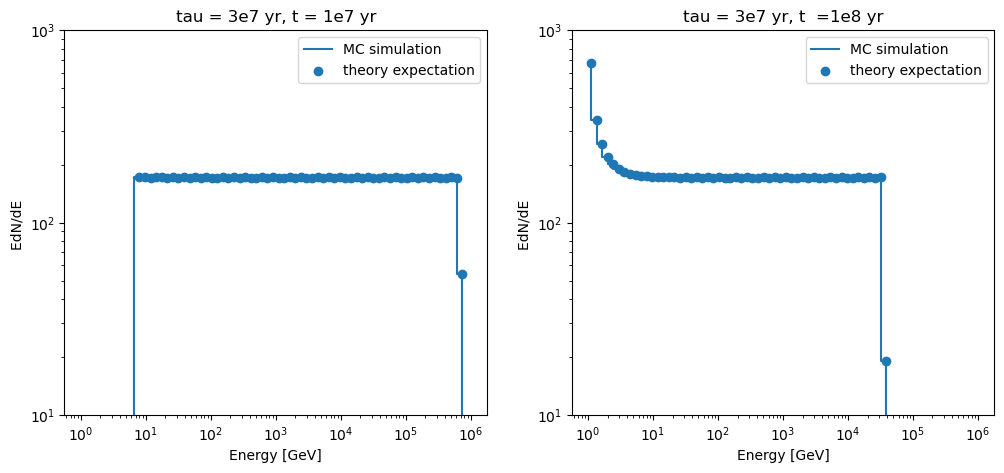

In [51]:
E_start = np.logspace(1,6,10000)
p_start = (E_start**2 - m_p**2)**0.5
tau = 3e7 # adiabatic loss timescale 

p_t1e8 = p_start*np.exp(-1e8 / tau)
E_t1e8 = np.sqrt(p_t1e8**2 + m_p**2)
p_t1e7 = p_start*np.exp(-1e7 / tau)
E_t1e7 = np.sqrt(p_t1e7**2 + m_p**2)
bins = np.logspace(0,6,71)

data_EdNdE_t1e7 = np.histogram(data_E_t1e7, bins = bins)[0]
data_EdNdE_t1e8 = np.histogram(data_E_t1e8, bins = bins)[0]

theory_t1e7 = np.histogram(E_t1e7, bins = bins)[0]
theory_t1e8 = np.histogram(E_t1e8, bins = bins)[0]

x = (bins[1:] + bins[:-1])/2
# x = (x**2 - m_p**2)**0.5
fig, axes = plt.subplots(1,2, figsize=(12,5))

axes[0].step(x, data_EdNdE_t1e7, label = "MC simulation")
axes[0].scatter(x, theory_t1e7, label = "theory expectation")
axes[1].step(x, data_EdNdE_t1e8, label = "MC simulation")
axes[1].scatter(x, theory_t1e8, label = "theory expectation")

for i in range(2):
    axes[i].set_xscale("log")
    axes[i].set_yscale("log")
    axes[i].legend()
    axes[i].set_xlabel("Energy [GeV]")
    axes[i].set_ylabel("EdN/dE ")
axes[0].set_ylim(1e1,1e3)
axes[1].set_ylim(1e1,1e3)
axes[0].set_title(f"tau = 3e7 yr, t = 1e7 yr")
axes[1].set_title(f"tau = 3e7 yr, t  =1e8 yr")


In [8]:
E

array([1.00324342e+00, 1.00338963e+00, 1.00353617e+00, ...,
       3.55919373e+04, 3.56329417e+04, 3.56739934e+04], shape=(10000,))